<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%2015%20PBL/Praktikum%201%20(JS15)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Praktikum 1 (JS14) PBL.ipynb

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models
import pickle

#Langkah 2: Load Dataset

In [2]:
# Memuat dataset
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Menggabungkan data berdasarkan cafe_id
df_merged = pd.merge(df_reviews, df_cafes, on='cafe_id', how='inner', suffixes=('_review', '_cafe'))

print(f"Jumlah baris data setelah digabung: {len(df_merged)}")
print("Kolom yang tersedia:", df_merged.columns.tolist())

Jumlah baris data setelah digabung: 2230
Kolom yang tersedia: ['review_id', 'cafe_id', 'author_name', 'rating_review', 'text', 'published_at', 'likes', 'scraped_at_review', 'name', 'address', 'latitude', 'longitude', 'rating_cafe', 'review_count', 'categories', 'phone', 'website', 'scraped_at_cafe', 'source_query']


#Langkah 3: Preprocessing & Ekstraksi Fitur Tabular

In [3]:
# Menentukan kolom target (Y) dan fitur (X)
target_column = 'rating_cafe' if 'rating_cafe' in df_merged.columns else 'rating'
df_merged = df_merged.dropna(subset=[target_column])

# Memilih fitur numerik dan kategorikal yang relevan
features_num = ['review_count', 'latitude', 'longitude']
features_cat = ['categories'] if 'categories' in df_merged.columns else []

X_raw = df_merged[features_num + features_cat].copy()
y = df_merged[target_column]

# Membersihkan missing value
X_raw = X_raw.dropna()
y = y.loc[X_raw.index]

print(f"Jumlah data setelah dibersihkan: {len(X_raw)}")

Jumlah data setelah dibersihkan: 2230


#Langkah 4: Transformasi Fitur (One-Hot Encoding & Scaling)

In [4]:
# Memisahkan kolom numerik dan kategorikal
num_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessor menggunakan ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

# Transformasi data X
X_processed = preprocessor.fit_transform(X_raw)

# Jika sparse matrix, ubah ke dense array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print(f"Dimensi fitur setelah preprocessing: {X_processed.shape}")

Dimensi fitur setelah preprocessing: (2230, 8)


#Langkah 5: Normalisasi & Konversi Bentuk Data

In [5]:
# Memastikan y berbentuk numpy array
y = np.array(y, dtype=np.float32)

print("Bentuk X_processed:", X_processed.shape)
print("Bentuk y:", y.shape)

Bentuk X_processed: (2230, 8)
Bentuk y: (2230,)


#Langkah 6: Split Data Training & Validation

In [6]:
# Split pertama: Memisahkan data training+val dengan data testing (80:20)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42
)

# Split kedua: Memisahkan data training dan data validation dari train_val (80:20)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=42
)

print(f"Jumlah data training   : {X_train.shape[0]}")
print(f"Jumlah data validation : {X_val.shape[0]}")
print(f"Jumlah data testing    : {X_test.shape[0]}")

Jumlah data training   : 1427
Jumlah data validation : 357
Jumlah data testing    : 446


#Langkah 7: Konversi Label ke Numpy Array

In [7]:
y_train = np.array(y_train, dtype=np.float32)
y_val   = np.array(y_val, dtype=np.float32)
y_test  = np.array(y_test, dtype=np.float32)

print("Tipe data y_train:", y_train.dtype)

Tipe data y_train: float32


#Langkah 8: Membangun Arsitektur Model Neural Network (Regressor)

In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)  # Output 1 neuron tanpa aktivasi untuk regresi nilai kontinu
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

#Langkah 9: Training Model

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 9.3330 - mae: 2.7658 - val_loss: 1.0751 - val_mae: 0.7894
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8252 - mae: 0.6980 - val_loss: 0.5062 - val_mae: 0.5666
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3822 - mae: 0.4803 - val_loss: 0.2615 - val_mae: 0.4007
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1925 - mae: 0.3353 - val_loss: 0.1326 - val_mae: 0.2801
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0950 - mae: 0.2351 - val_loss: 0.0724 - val_mae: 0.2081
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0508 - mae: 0.1726 - val_loss: 0.0458 - val_mae: 0.1645
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0336 - mae: 0.1430 - val_loss: 0.0336 - val_mae: 0.1397
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0254 - mae: 0.1234 - val_loss: 0.0278 - val_mae: 0.1227
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0213 - mae: 

#Langkah 10: Evaluasi Model

In [10]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"Test Loss (MSE): {test_loss:.4f}")
print(f"Test MAE: {test_mae:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0113 - mae: 0.0784 
Test Loss (MSE): 0.0113
Test MAE: 0.0784


#Langkah 11: Prediksi, Evaluasi Metrik ($R^2$), & Visualisasi

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
R2 Score Model Neural Network: 0.5872


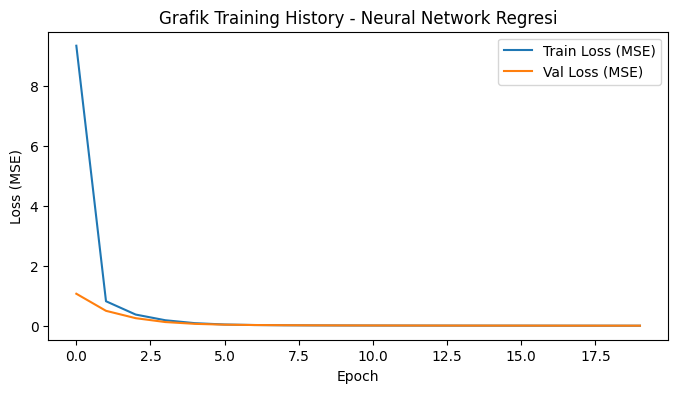

In [11]:
# Prediksi data test
y_pred = model.predict(X_test).flatten()

# Hitung R2 Score
r2 = r2_score(y_test, y_pred)
print(f"R2 Score Model Neural Network: {r2:.4f}")

# Visualisasi riwayat training (Loss)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Val Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Grafik Training History - Neural Network Regresi')
plt.legend()
plt.show()

#Langkah 12: Menyimpan Model dan Preprocessor (Artifacts)

In [12]:
import pickle

# 1. Simpan Model Neural Network
model.save('cafe_regressor_model.h5')
print("✅ Model berhasil disimpan sebagai: cafe_regressor_model.h5")

# 2. Simpan Preprocessor (ColumnTransformer)
with open('preprocessor.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)
print("✅ Preprocessor berhasil disimpan sebagai: preprocessor.pkl")

✅ Model berhasil disimpan sebagai: cafe_regressor_model.h5
✅ Preprocessor berhasil disimpan sebagai: preprocessor.pkl
